## import libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute        import SimpleImputer, KNNImputer
from sklearn.preprocessing import (OrdinalEncoder, OneHotEncoder,
                                StandardScaler, MinMaxScaler,
                                RobustScaler, PowerTransformer)
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, KFold, StratifiedKFold
from scipy.ndimage           import gaussian_filter1d
from scipy.stats             import zscore
from sklearn.naive_bayes import GaussianNB, BernoulliNB, ComplementNB
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import learning_curve
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.preprocessing import PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import VotingClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import VotingRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# Ensemble Models
from sklearn.ensemble import (
    BaggingClassifier,
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    StackingClassifier
)


## load data

In [3]:
df = pd.read_csv("Fifa.csv")
print(f'Shape: {df.shape}')
df.head()

Shape: (19667, 9)


,Name,Country,Position,Age,Overall_Rating,Future Potential,Team,Value Per M$,Total_Stats Score
0,Agostinho Mabululu,Angola,LW,30,68,68,Ittihad Alexandria,0.65,1660
1,Mahmoud Gennesh,Egypt,GK,35,67,67,Ittihad Alexandria,0.35,1620
2,Sobhi Suleiman,Egypt,GK,28,63,65,Ittihad Alexandria,0.20,1480
3,Mahmoud Alaa,Egypt,CB,32,68,68,Ittihad Alexandria,0.50,1695
4,Mahmoud Shabana,Egypt,CB,30,66,66,Ittihad Alexandria,0.40,1640


## EDA

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19667 entries, 0 to 19666
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Name               19667 non-null  object 
 1   Country            19667 non-null  object 
 2   Position           19667 non-null  object 
 3   Age                19667 non-null  int64  
 4   Overall_Rating     19667 non-null  int64  
 5   Future Potential   19667 non-null  int64  
 6   Team               19667 non-null  object 
 7   Value Per M$       19667 non-null  float64
 8   Total_Stats Score  19667 non-null  int64  
dtypes: float64(1), int64(4), object(4)
memory usage: 1.4+ MB


In [5]:
df.describe()

,Age,Overall_Rating,Future Potential,Value Per M$,Total_Stats Score
count,19667.000000,19667.000000,19667.000000,19667.000000,19667.000000
mean,22.990034,63.225403,70.658718,2.514639,1534.513907
std,4.692410,7.812716,6.489551,7.256974,283.248088
min,15.000000,36.000000,46.000000,0.000000,416.000000
25%,19.000000,58.000000,66.000000,0.325000,1388.000000
50%,22.000000,63.000000,70.000000,0.675000,1549.000000
75%,26.000000,68.000000,75.000000,1.600000,1720.000000
max,44.000000,91.000000,95.000000,190.500000,2324.000000


In [6]:
# check for missing values
df.isnull().sum()

Name                 0
Country              0
Position             0
Age                  0
Overall_Rating       0
Future Potential     0
Team                 0
Value Per M$         0
Total_Stats Score    0
dtype: int64

No missing values at any column

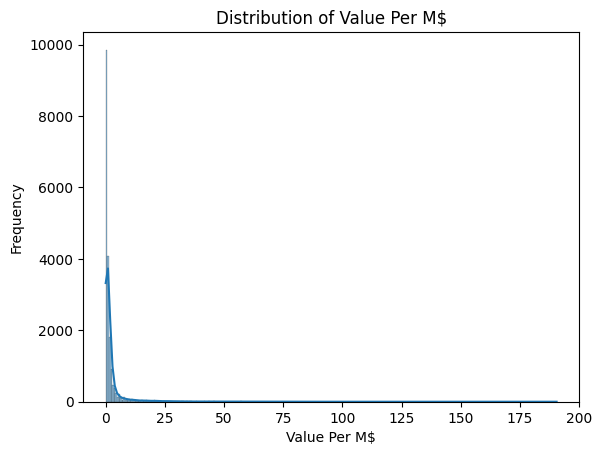

In [7]:
# distribution of the Value Per M$
sns.histplot(df['Value Per M$'], kde=True)
plt.title('Distribution of Value Per M$')
plt.xlabel('Value Per M$')
plt.ylabel('Frequency')
plt.show()

Value Per M$ is skewed so we will compute it

In [8]:
# compute skewness of the Value Per M$ column
skewness = df['Value Per M$'].skew()
print(f'Skewness of Value Per M$: {skewness}')

Skewness of Value Per M$: 7.983215201865151


In [9]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

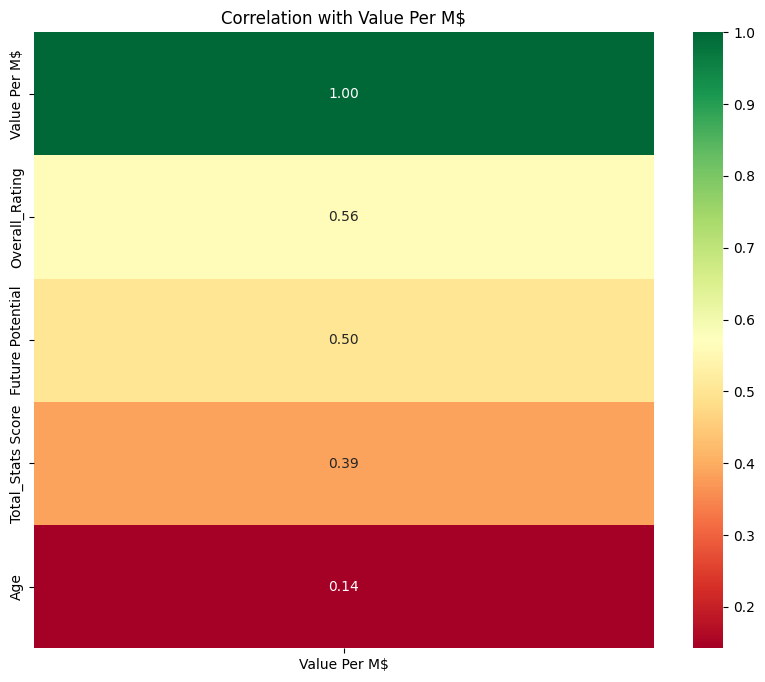

In [10]:
# correlation heatmap numerical features related to Value Per M$
numeric_df = df.select_dtypes(include=['float64', 'int64'])
value_corr = numeric_df.corr()[['Value Per M$']].sort_values(by='Value Per M$', ascending=False)
plt.figure(figsize=(10, 8))
sns.heatmap(value_corr, annot=True, cmap='RdYlGn', fmt=".2f", cbar=True)

plt.title('Correlation with Value Per M$')
plt.show()

most correlated numeric feature to Value per M$ is overall_Ratio

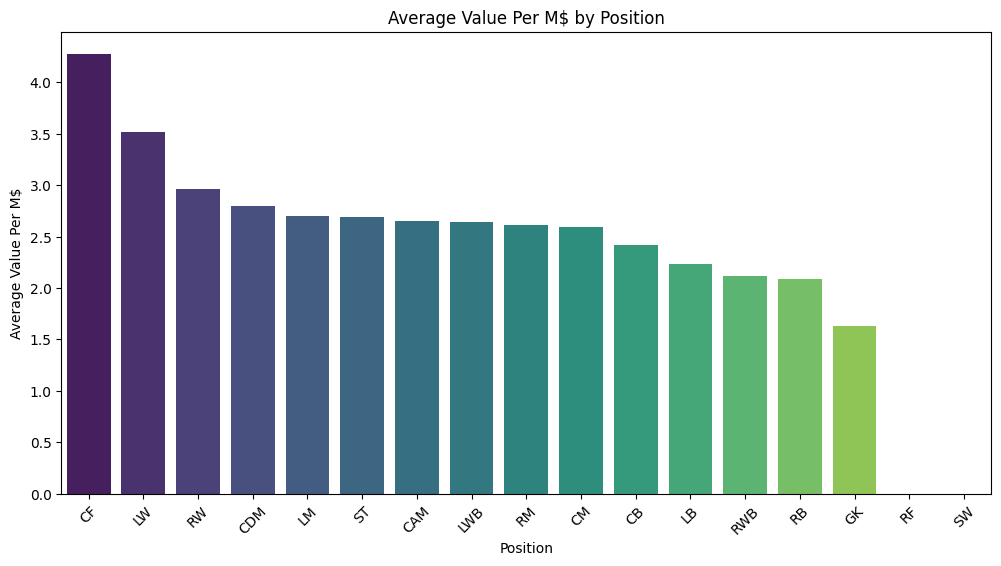

Position
CF     4.275464
LW     3.514044
RW     2.960311
CDM    2.794871
LM     2.698206
ST     2.693708
CAM    2.647508
LWB    2.639900
RM     2.613791
CM     2.593153
CB     2.415783
LB     2.237861
RWB    2.114141
RB     2.084400
GK     1.632672
RF     0.000000
SW     0.000000
Name: Value Per M$, dtype: float64


In [11]:
# What is the average Overall_Rating per Position?

avg_value_by_position = df.groupby('Position')['Value Per M$'].mean().sort_values(ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(x=avg_value_by_position.index, y=avg_value_by_position.values, palette='viridis')
plt.title('Average Value Per M$ by Position')
plt.xlabel('Position')
plt.ylabel('Average Value Per M$')
plt.xticks(rotation=45)
plt.show()

print(avg_value_by_position)

## visualize data

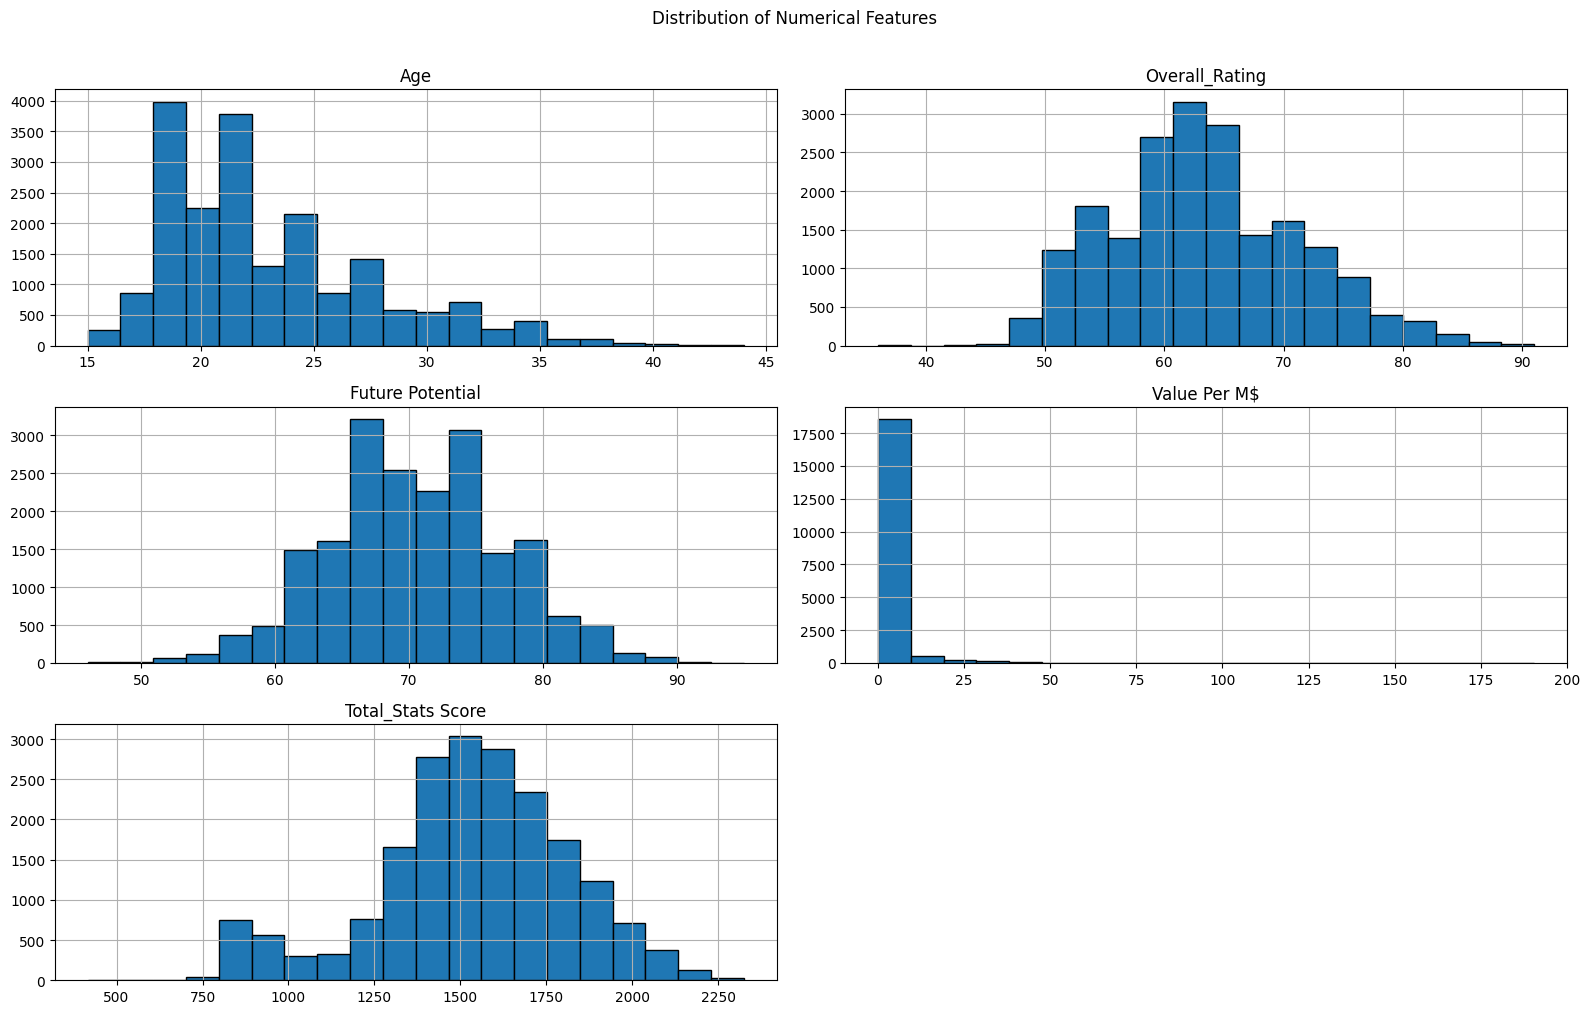

In [12]:
# Numerical Features Distribution

num_cols = df.select_dtypes(include=np.number).columns.tolist()

df[num_cols].hist(figsize=(16, 10), bins=20, edgecolor='black')
plt.suptitle('Distribution of Numerical Features', y=1.01)
plt.tight_layout()
plt.show()

## Train / Test Split

In [13]:
train, test = train_test_split(
    df, test_size=0.2, random_state=1
)

In [14]:
print(f'Train: {train.shape}  |  Test: {test.shape}')

Train: (15733, 9)  |  Test: (3934, 9)


## Preprocessing

no null values


In [15]:
for x in train.index:
    if train.loc[x, "Value Per M$"] == 0:
        train.drop(x, inplace=True)

train.reset_index(drop=True, inplace=True)

for x in test.index:
    if test.loc[x, "Value Per M$"] == 0:
        test.drop(x, inplace=True)

test.reset_index(drop=True, inplace=True)

for x in train.index:
    if train.loc[x, "Overall_Rating"] == 0:
        train.drop(x, inplace=True)

train.reset_index(drop=True, inplace=True)

for x in test.index:
    if test.loc[x, "Overall_Rating"] == 0:
        test.drop(x, inplace=True)

test.reset_index(drop=True, inplace=True)

<Figure size 600x300 with 0 Axes>

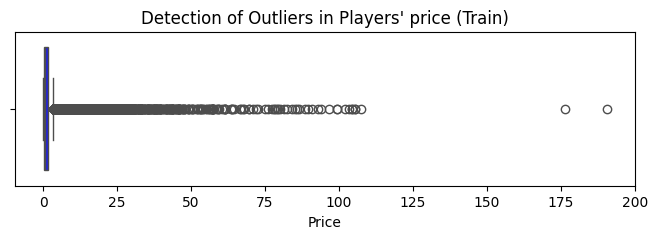

In [16]:
# Visualise with box plot
plt.figure(figsize=(6, 3))
plt.figure(figsize=(8, 2))
sns.boxplot(x=train['Value Per M$'], color='blue')
plt.title('Detection of Outliers in Players\' price (Train)')
plt.xlabel('Price')
plt.show()

In [17]:
# handling outliers
Q1  = train['Value Per M$'].quantile(0.25)
Q3  = train['Value Per M$'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

outliers_iqr = train[(train['Value Per M$'] < lower) | (train['Value Per M$'] > upper)]
print(f'IQR outliers in player\'s price: {len(outliers_iqr)}')
train = train[(train['Value Per M$'] >= lower) & (train['Value Per M$'] <= upper)]
test['Value Per M$'] = test['Value Per M$'].clip(lower, upper)
print(f'After IQR outlier removal: {train.shape}')



IQR outliers in player's price: 1935
After IQR outlier removal: (13530, 9)


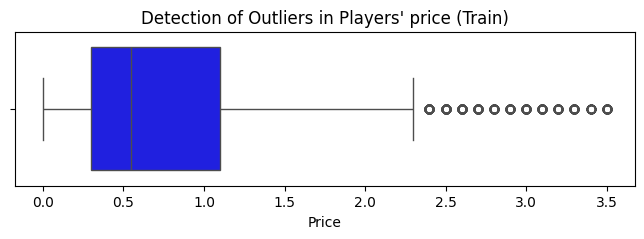

In [18]:

plt.figure(figsize=(8, 2))
sns.boxplot(x=train['Value Per M$'], color='blue')
plt.title('Detection of Outliers in Players\' price (Train)')
plt.xlabel('Price')
plt.show()

In [19]:
numerical_cols = train.select_dtypes(include=['float64', 'int64']).columns.tolist()

#### encoding categorical features


In [20]:
categorical_cols = train.select_dtypes(include=['object']).columns.tolist()
print(f'Categorical features: {categorical_cols}')

train = pd.get_dummies(train, columns= ["Position"], dtype=int, drop_first=True)
test  = pd.get_dummies(test,  columns= ["Position"], dtype=int, drop_first=True)

test = test.reindex(columns=train.columns, fill_value=0)
# encode Position using OrdinalEncoder
ord_features = ['Team','Country']
oe = OrdinalEncoder( handle_unknown='use_encoded_value', unknown_value=-1)
train[ord_features] = oe.fit_transform(train[ord_features])
test[ord_features]  = oe.transform(test[ord_features])

print(f'Train shape after encoding: {train.shape}')
print(f'Test shape after encoding: {test.shape}')

train = train.reset_index(drop=True)
test = test.reset_index(drop=True)
print(train.head())

Categorical features: ['Name', 'Country', 'Position', 'Team']
Train shape after encoding: (13530, 22)
Test shape after encoding: (3872, 22)
                     Name  Country  Age  Overall_Rating  Future Potential  \
0        Ante Majstorović     31.0   27              70                72   
1  Javier Llario Moscardó    132.0   22              60                69   
2        Fernando Benítez    110.0   21              62                70   
3          Peter Urminsky    128.0   23              58                65   
4    Maximilian Neuberger     52.0   22              61                69   

    Team  Value Per M$  Total_Stats Score  Position_CB  Position_CDM  ...  \
0  728.0          1.70               1541            1             0  ...   
1   49.0          0.55               1514            0             0  ...   
2  763.0          0.90               1415            0             0  ...   
3  767.0          0.35                841            0             0  ...   
4  418.0    

##### scaling Team and Country features


In [21]:
print(f'Categorical features: {train[ord_features].columns.tolist()}')
scaler = MinMaxScaler(feature_range=(0, 1))
train[ord_features] = scaler.fit_transform(train[ord_features])
test[ord_features]  = scaler.transform(test[ord_features])


Categorical features: ['Team', 'Country']


In [22]:
# scaling numerical features

print(f'Numerical features: {numerical_cols}')
scaler = MinMaxScaler(feature_range=(0, 1))
train[numerical_cols] = scaler.fit_transform(train[numerical_cols])
test[numerical_cols] = scaler.transform(test[numerical_cols])
train.head()

Numerical features: ['Age', 'Overall_Rating', 'Future Potential', 'Value Per M$', 'Total_Stats Score']


,Name,Country,Age,Overall_Rating,Future Potential,Team,Value Per M$,Total_Stats Score,Position_CB,Position_CDM,...,Position_GK,Position_LB,Position_LM,Position_LW,Position_LWB,Position_RB,Position_RM,Position_RW,Position_RWB,Position_ST
0,Ante Majstorović,0.200000,0.392857,0.666667,0.650,0.785329,0.485567,0.564940,1,0,...,0,0,0,0,0,0,0,0,0,0
1,Javier Llario Moscardó,0.851613,0.214286,0.410256,0.575,0.052859,0.156902,0.545777,0,0,...,0,0,1,0,0,0,0,0,0,0
2,Fernando Benítez,0.709677,0.178571,0.461538,0.600,0.823085,0.256931,0.475515,0,0,...,0,0,1,0,0,0,0,0,0,0
3,Peter Urminsky,0.825806,0.250000,0.358974,0.475,0.827400,0.099743,0.068133,0,0,...,1,0,0,0,0,0,0,0,0,0
4,Maximilian Neuberger,0.335484,0.214286,0.435897,0.575,0.450917,0.199771,0.519517,0,0,...,0,0,0,0,0,1,0,0,0,0


In [23]:
# save to csv
train.to_csv('train.csv', index=False)
test.to_csv('test.csv', index=False)

## Create Classification Target (Logistic Regression + Naïve Bayes)

In [24]:
print(train['Overall_Rating'].describe())

count    13530.000000
mean         0.442394
std          0.158121
min          0.000000
25%          0.333333
50%          0.461538
75%          0.564103
max          1.000000
Name: Overall_Rating, dtype: float64


In [25]:
p50 = train['Overall_Rating'].quantile(0.50)
p75 = train['Overall_Rating'].quantile(0.75)
p95 = train['Overall_Rating'].quantile(0.95)
bins = [-float('inf'), p50, p75, p95, float('inf')]
labels = ['Low', 'Mid', 'High', 'Elite']

# define target variable for classification
train['Performance_Tier'] = pd.cut(train['Overall_Rating'], bins=bins, labels=labels)
test['Performance_Tier'] = pd.cut(test['Overall_Rating'], bins=bins, labels=labels)

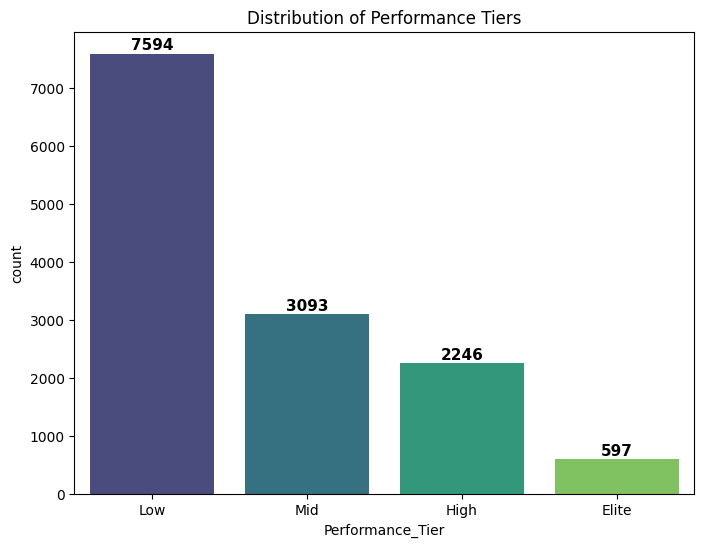

Performance_Tier
Low      56.127125
Mid      22.860310
High     16.600148
Elite     4.412417
Name: proportion, dtype: float64


In [26]:
plt.figure(figsize=(8, 6))

ax = sns.countplot(data=train, x='Performance_Tier', palette='viridis',
                order=['Low', 'Mid', 'High', 'Elite'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 6),
                textcoords='offset points',
                fontsize=11,
                fontweight='bold')

plt.title('Distribution of Performance Tiers')
plt.show()

print(train['Performance_Tier'].value_counts(normalize=True) * 100)

# Task 4
## Polynomial Regreission

### Baseline Linear Regression model


In [27]:
# Separate X and y
X_train_poly = train.select_dtypes(include=[np.number]).drop(columns=['Value Per M$'], errors='ignore')
y_train_poly = train['Value Per M$']

X_test_poly = test.select_dtypes(include=[np.number]).drop(columns=['Value Per M$'], errors='ignore')
y_test_poly = test['Value Per M$']

lr_baseline = LinearRegression()
lr_baseline.fit(X_train_poly, y_train_poly)

y_pred_train_poly = lr_baseline.predict(X_train_poly)
y_pred_test_poly = lr_baseline.predict(X_test_poly)

# Evaluateing the model
def evaluate_model(y_true_poly, y_pred_poly, dataset_name=""):
    mae = mean_absolute_error(y_true_poly, y_pred_poly)
    mse = mean_squared_error(y_true_poly, y_pred_poly)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true_poly, y_pred_poly)

    print(f"{dataset_name} Performance ")
    print(f"MAE:  {mae:.4f}")
    print(f"MSE:  {mse:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"R²:   {r2:.4f}\n")

print("Baseline Linear Regression:")

evaluate_model(y_train_poly, y_pred_train_poly, "Train")
evaluate_model(y_test_poly, y_pred_test_poly, "Test")

Baseline Linear Regression:
Train Performance 
MAE:  0.0794
MSE:  0.0113
RMSE: 0.1061
R²:   0.7514

Test Performance 
MAE:  0.1050
MSE:  0.0210
RMSE: 0.1451
R²:   0.7950



### Polynomial Features to expand the numerical features


Degree 1 | Train R²: 0.7514 | Test R²: 0.7950
Degree 2 | Train R²: 0.9364 | Test R²: 0.7133
Degree 3 | Train R²: 0.9612 | Test R²: 0.0069
Degree 4 | Train R²: 0.9674 | Test R²: -0.2774


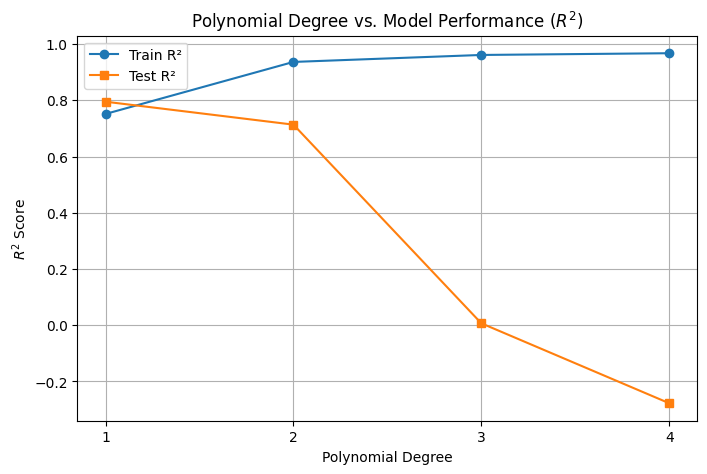

In [28]:
# Identify numerical vs encoded/categorical features
num_features = ['Age', 'Overall_Rating', 'Future Potential', 'Total_Stats Score']
cat_features = [col for col in X_train_poly.columns if col not in num_features]

degrees = [1, 2, 3, 4]

train_r2_scores_poly = []
test_r2_scores_poly = []

# Transform only numerical features, let categorical features pass
for d in degrees:

    preprocessor_poly = ColumnTransformer(
        transformers=[
            ('poly', PolynomialFeatures(degree=d, include_bias=False), num_features),
            ('passthrough', 'passthrough', cat_features)
        ]
    )

    poly_model = Pipeline(steps=[
        ('preprocessor', preprocessor_poly),
        ('regressor', LinearRegression())
    ])

    poly_model.fit(X_train_poly, y_train_poly)

    train_r2_poly = r2_score(
        y_train_poly,
        poly_model.predict(X_train_poly)
    )

    test_r2_poly = r2_score(
        y_test_poly,
        poly_model.predict(X_test_poly)
    )

    train_r2_scores_poly.append(train_r2_poly)
    test_r2_scores_poly.append(test_r2_poly)

    print(
        f"Degree {d} | "
        f"Train R²: {train_r2_poly:.4f} | "
        f"Test R²: {test_r2_poly:.4f}"
    )


# Plotting the Trend
plt.figure(figsize=(8, 5))

plt.plot(
    degrees,
    train_r2_scores_poly,
    marker='o',
    label='Train R²'
)

plt.plot(
    degrees,
    test_r2_scores_poly,
    marker='s',
    label='Test R²'
)

plt.title('Polynomial Degree vs. Model Performance ($R^2$)')

plt.xlabel('Polynomial Degree')
plt.ylabel('$R^2$ Score')

plt.xticks(degrees)

plt.legend()
plt.grid(True)

plt.show()

### Which degree gives the best generalization? Justify using the train/test gap.
Degree 2 gives the best generalization (small difference between train and test), then degree 3 (bigger difference between train and test). Degree 4 score exceptionally high on the Train set but crash completely on the Test set (a negative $R^2$), signaling severe overfitting

### Regularization (Ridge and Lasso)

Best Ridge Alpha: 16.7683 | Test RMSE: 0.1123
Best Lasso Alpha: 0.0007 | Test RMSE: 0.1125


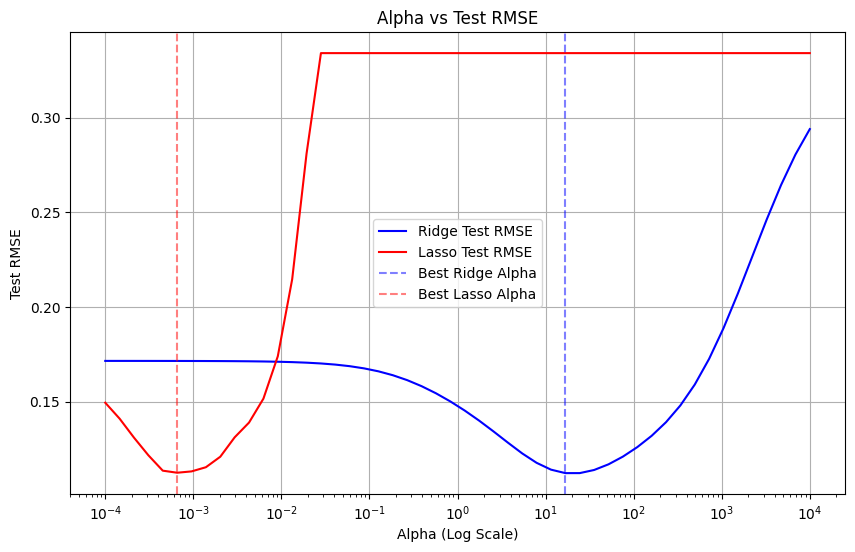

In [29]:
best_degree_poly = 2

# Prepare the data with the best polynomial degree explicitly
best_preprocessor_poly = ColumnTransformer(
    transformers=[
        ('poly', PolynomialFeatures(degree=best_degree_poly, include_bias=False), num_features),
        ('passthrough', 'passthrough', cat_features)
    ]
)

X_train_poly_transformed = best_preprocessor_poly.fit_transform(X_train_poly)
X_test_poly_transformed = best_preprocessor_poly.transform(X_test_poly)

# Log-spaced alphas
alphas_poly = np.logspace(-4, 4, 50)

ridge_train_rmse_poly = []
ridge_test_rmse_poly = []

lasso_train_rmse_poly = []
lasso_test_rmse_poly = []

for alpha_poly in alphas_poly:

    ridge_poly = Ridge(alpha=alpha_poly, max_iter=10000)

    ridge_poly.fit(X_train_poly_transformed, y_train_poly)

    ridge_train_rmse_poly.append(
        np.sqrt(
            mean_squared_error(
                y_train_poly,
                ridge_poly.predict(X_train_poly_transformed)
            )
        )
    )

    ridge_test_rmse_poly.append(
        np.sqrt(
            mean_squared_error(
                y_test_poly,
                ridge_poly.predict(X_test_poly_transformed)
            )
        )
    )


    lasso_poly = Lasso(alpha=alpha_poly, max_iter=10000)

    lasso_poly.fit(X_train_poly_transformed, y_train_poly)

    lasso_train_rmse_poly.append(
        np.sqrt(
            mean_squared_error(
                y_train_poly,
                lasso_poly.predict(X_train_poly_transformed)
            )
        )
    )

    lasso_test_rmse_poly.append(
        np.sqrt(
            mean_squared_error(
                y_test_poly,
                lasso_poly.predict(X_test_poly_transformed)
            )
        )
    )

# Identify best alphas
best_ridge_alpha_poly = alphas_poly[np.argmin(ridge_test_rmse_poly)]

best_lasso_alpha_poly = alphas_poly[np.argmin(lasso_test_rmse_poly)]

print(
    f"Best Ridge Alpha: {best_ridge_alpha_poly:.4f} | "
    f"Test RMSE: {min(ridge_test_rmse_poly):.4f}"
)

print(
    f"Best Lasso Alpha: {best_lasso_alpha_poly:.4f} | "
    f"Test RMSE: {min(lasso_test_rmse_poly):.4f}"
)

# Plotting the Alpha Sweep
plt.figure(figsize=(10, 6))

plt.plot(
    alphas_poly,
    ridge_test_rmse_poly,
    label='Ridge Test RMSE',
    color='blue'
)

plt.plot(
    alphas_poly,
    lasso_test_rmse_poly,
    label='Lasso Test RMSE',
    color='red'
)

plt.axvline(
    best_ridge_alpha_poly,
    color='blue',
    linestyle='--',
    alpha=0.5,
    label='Best Ridge Alpha'
)

plt.axvline(
    best_lasso_alpha_poly,
    color='red',
    linestyle='--',
    alpha=0.5,
    label='Best Lasso Alpha'
)

plt.xscale('log')

plt.title('Alpha vs Test RMSE')

plt.xlabel('Alpha (Log Scale)')
plt.ylabel('Test RMSE')

plt.legend()
plt.grid(True)

plt.show()

In [30]:
# Re-fit the best Lasso model to check feature coefficients
best_lasso_model_poly = Lasso(alpha=best_lasso_alpha_poly,max_iter=10000)

best_lasso_model_poly.fit(X_train_poly_transformed,y_train_poly)

# Count how many features were zeroed out
zeroed_out_count_poly = np.sum(best_lasso_model_poly.coef_ == 0)

total_features_poly = len(best_lasso_model_poly.coef_)
print(
    f"Lasso zeroed out "
    f"{zeroed_out_count_poly} out of "
    f"{total_features_poly} features."
)

# Name of features were zeroed out
feature_names_poly = best_preprocessor_poly.get_feature_names_out()

zeroed_features_poly = np.array(feature_names_poly)[best_lasso_model_poly.coef_ == 0]

print("----" * 20)

print(zeroed_features_poly)

Lasso zeroed out 24 out of 30 features.
--------------------------------------------------------------------------------
['poly__Age' 'poly__Overall_Rating' 'poly__Future Potential'
 'poly__Total_Stats Score' 'poly__Age Overall_Rating'
 'poly__Age Future Potential' 'poly__Age Total_Stats Score'
 'poly__Future Potential^2' 'poly__Future Potential Total_Stats Score'
 'poly__Total_Stats Score^2' 'passthrough__Country' 'passthrough__Team'
 'passthrough__Position_CDM' 'passthrough__Position_CF'
 'passthrough__Position_CM' 'passthrough__Position_GK'
 'passthrough__Position_LB' 'passthrough__Position_LM'
 'passthrough__Position_LW' 'passthrough__Position_LWB'
 'passthrough__Position_RB' 'passthrough__Position_RM'
 'passthrough__Position_RW' 'passthrough__Position_RWB']


### Compare Ridge vs. Lasso: which performs better on this dataset, and why?
Because the data contains alot of One-Hot Encoded columns, Ridge usually outperforms Lasso on error metrics (RMSE)
### Did Lasso zero out any features? If yes, which ones and what does that imply?
It did zeroed 24 out of 30 features.
It implies that those specific features don't provide meaningful predictive power for a player's Market Value

# Task 5 :Logistic Regression

In [31]:
X_train_log = train.select_dtypes(include=[np.number]).drop(columns=['Performance_Tier','Overall_Rating'], errors='ignore')
y_train_log = train['Performance_Tier']
X_test_log = test.select_dtypes(include=[np.number]).drop(columns=['Performance_Tier','Overall_Rating'], errors='ignore')
y_test_log = test['Performance_Tier']

## Training the Model
### We instantiate the LogisticRegression model from sklearn and fit it to our training data.

In [32]:
logmodel_log = LogisticRegression()

logmodel_log.fit(X_train_log,y_train_log)

y_pred_log = logmodel_log.predict(X_test_log)

##  Model Evaluation

In [33]:
accuracy_log = accuracy_score(y_test_log, y_pred_log)
precision_log = precision_score(y_test_log, y_pred_log, average='weighted')
recall_log    = recall_score(y_test_log, y_pred_log, average='weighted')
f1_log        = f1_score(y_test_log, y_pred_log, average='weighted')

print("Accuracy:", accuracy_log)
print("Precision (Weighted):", precision_log)
print("Recall (Weighted):", recall_log)
print("F1 Score (Weighted):", f1_log)

Accuracy: 0.8985020661157025
Precision (Weighted): 0.9015583897869422
Recall (Weighted): 0.8985020661157025
F1 Score (Weighted): 0.8989562874796287


## Confusion Matrix

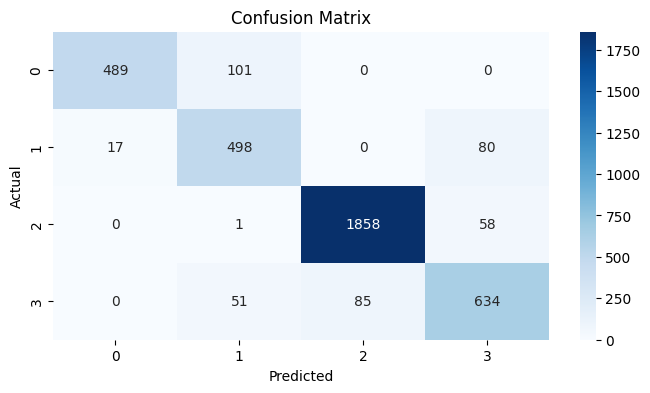

In [34]:
cm_log = confusion_matrix(y_test_log, y_pred_log)
plt.figure(figsize=(8, 4))
sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [35]:
print("Classification Report:")
print(classification_report(y_test_log, y_pred_log, target_names=['Low', 'Mid', 'High', 'Elite']))

Classification Report:
              precision    recall  f1-score   support

         Low       0.97      0.83      0.89       590
         Mid       0.76      0.84      0.80       595
        High       0.96      0.97      0.96      1917
       Elite       0.82      0.82      0.82       770

    accuracy                           0.90      3872
   macro avg       0.88      0.86      0.87      3872
weighted avg       0.90      0.90      0.90      3872



## The C-Sweep part (searching for the best C)

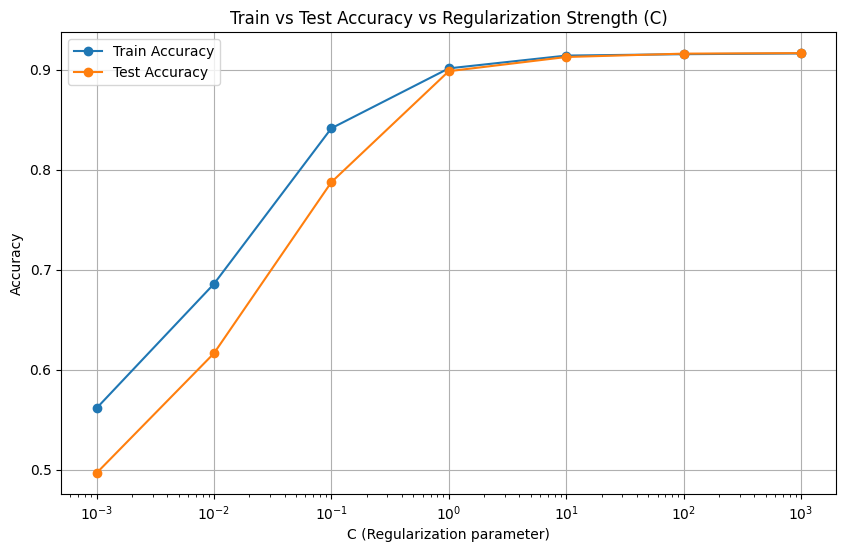

Best C value identified: 1000.0


In [36]:
C_range_log = np.logspace(-3, 3, 7)
train_acc_log = []
test_acc_log = []

for c_log in C_range_log:
    model_log = LogisticRegression(C=c_log, max_iter=1000)
    model_log.fit(X_train_log, y_train_log)

    train_acc_log.append(model_log.score(X_train_log, y_train_log))
    test_acc_log.append(model_log.score(X_test_log, y_test_log))

plt.figure(figsize=(10, 6))
plt.semilogx(C_range_log, train_acc_log, label='Train Accuracy', marker='o')
plt.semilogx(C_range_log, test_acc_log, label='Test Accuracy', marker='o')
plt.title('Train vs Test Accuracy vs Regularization Strength (C)')
plt.xlabel('C (Regularization parameter)')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

best_c_log = C_range_log[np.argmax(test_acc_log)]
print(f"Best C value identified: {best_c_log}")

## The comparison between L1 (Saga) and L2 (Lbfgs)

In [37]:
l1_model_log = LogisticRegression(penalty='l1', C=best_c_log, solver='saga', max_iter=5000)
l1_model_log.fit(X_train_log, y_train_log)
l1_score_log = l1_model_log.score(X_test_log, y_test_log)

l2_model_log = LogisticRegression(penalty='l2', C=best_c_log, solver='lbfgs', max_iter=5000)
l2_model_log.fit(X_train_log, y_train_log)
l2_score_log = l2_model_log.score(X_test_log, y_test_log)

print(f"Accuracy with L1 (Saga): {l1_score_log:.4f}")
print(f"Accuracy with L2 (Lbfgs): {l2_score_log:.4f}")

if l1_score_log > l2_score_log:
    print("L1 Regularization performed better.")
else:
    print("L2 Regularization performed better.")

Accuracy with L1 (Saga): 0.9158
Accuracy with L2 (Lbfgs): 0.9166
L2 Regularization performed better.


## Task 6 : Model 3: Naïve Bayes Classification
### 1- GaussianNB — train on numerical features only (Age, Future Potential, Total_Stats Score)

#### Befor scaling

In [38]:
num_cols = ['Age', 'Future Potential', 'Total_Stats Score']
y_train=train['Performance_Tier']
y_test=test['Performance_Tier']
X_train_gauss = train[num_cols]
X_test_gauss = test[num_cols]

gnb = GaussianNB()
gnb.fit(X_train_gauss, y_train)

y_pred_gauss = gnb.predict(X_test_gauss)

print("Accuracy:", accuracy_score(y_test, y_pred_gauss))
print("")
print(classification_report(y_test, y_pred_gauss))

Accuracy: 0.6776859504132231

              precision    recall  f1-score   support

       Elite       0.96      0.18      0.31       590
        High       0.42      0.57      0.48       595
         Low       0.80      0.95      0.87      1917
         Mid       0.51      0.46      0.48       770

    accuracy                           0.68      3872
   macro avg       0.67      0.54      0.54      3872
weighted avg       0.71      0.68      0.65      3872



#### After scaling

In [39]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_gauss)
X_test_scaled = scaler.transform(X_test_gauss)

gnb_scaled = GaussianNB()

gnb_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = gnb_scaled.predict(X_test_scaled)

acc_scaled = accuracy_score(y_test, y_pred_scaled)

print("\nGaussianNB WITH StandardScaler")
print("Accuracy:", acc_scaled)
print(classification_report(y_test, y_pred_scaled))


GaussianNB WITH StandardScaler


Accuracy: 0.6776859504132231
              precision    recall  f1-score   support

       Elite       0.96      0.18      0.31       590
        High       0.42      0.57      0.48       595
         Low       0.80      0.95      0.87      1917
         Mid       0.51      0.46      0.48       770

    accuracy                           0.68      3872
   macro avg       0.67      0.54      0.54      3872
weighted avg       0.71      0.68      0.65      3872



The performance of GaussianNB remained identical before and after applying StandardScaler. This happens because GaussianNB models each feature independently using its mean and variance, and scaling changes both values proportionally without changing the underlying probability distribution significantly. Therefore, GaussianNB is generally not highly sensitive to feature scaling compared to distance-based algorithms such as KNN or SVM.

### BernoulliNB — train on the full OHE-encoded feature set (binary columns)

In [40]:
binary_cols = [col for col in train.columns if train[col].nunique() == 2]

X_train_ber = train[binary_cols]
X_test_ber = test[binary_cols]

bnb = BernoulliNB()
bnb.fit(X_train_ber, y_train)

y_pred_ber = bnb.predict(X_test_ber)

print("Accuracy:", accuracy_score(y_test, y_pred_ber))
print(classification_report(y_test, y_pred_ber))

Accuracy: 0.49509297520661155
              precision    recall  f1-score   support

       Elite       0.00      0.00      0.00       590
        High       0.00      0.00      0.00       595
         Low       0.50      1.00      0.66      1917
         Mid       0.00      0.00      0.00       770

    accuracy                           0.50      3872
   macro avg       0.12      0.25      0.17      3872
weighted avg       0.25      0.50      0.33      3872



### ComplementNB — train on the full OHE-encoded feature set (shifted to non-negative)

In [41]:
X_train_compl = train.drop(columns=['Performance_Tier','Name'])
X_test_comple = test.drop(columns=['Performance_Tier','Name'])

scaler = MinMaxScaler()
X_train_compl = scaler.fit_transform(X_train_compl)
X_test_compl = scaler.transform(X_test_comple)

cnb = ComplementNB()
cnb.fit(X_train_compl, y_train)

y_pred_compl = cnb.predict(X_test_compl)

print("Accuracy:", accuracy_score(y_test, y_pred_compl))
print(classification_report(y_test, y_pred_compl))

Accuracy: 0.5260847107438017
              precision    recall  f1-score   support

       Elite       0.00      0.00      0.00       590
        High       0.30      0.79      0.43       595
         Low       0.79      0.75      0.77      1917
         Mid       0.29      0.18      0.22       770

    accuracy                           0.53      3872
   macro avg       0.34      0.43      0.36      3872
weighted avg       0.49      0.53      0.49      3872



#### comparsion

In [42]:
print("GaussianNB Accuracy :", accuracy_score(y_test, y_pred_gauss))
print("BernoulliNB Accuracy:", accuracy_score(y_test, y_pred_ber))
print("ComplementNB Accuracy:", accuracy_score(y_test, y_pred_compl))

GaussianNB Accuracy : 0.6776859504132231
BernoulliNB Accuracy: 0.49509297520661155
ComplementNB Accuracy: 0.5260847107438017


### Task 7: K-Fold cross and stratified K-Fold cross

In [43]:
X_cross = train.drop(columns=['Value Per M$', 'Performance_Tier','Name'], errors='ignore')
y_cross = train['Value Per M$']

best_cross_pipeline = Pipeline(steps=[
    ('preprocessor', best_preprocessor_poly),
    ('regressor', Ridge(alpha=best_ridge_alpha_poly))
])

kf = KFold(n_splits=5, shuffle=True, random_state=42)

cross_vali_score = cross_val_score(best_cross_pipeline, X_cross, y_cross, cv=kf, scoring='neg_mean_squared_error')
rmse_scores = np.sqrt(-cross_vali_score)

mean_rmse_cross= rmse_scores.mean()
std_rmse_cross= rmse_scores.std()

print(f"Individual Fold RMSE: {rmse_scores}")
print(f"Mean RMSE: {mean_rmse_cross}")
print(f"Standard Deviation: {std_rmse_cross}")

Individual Fold RMSE: [0.07597234 0.0775369  0.07652615 0.07773186 0.07992336]
Mean RMSE: 0.0775381225541589
Standard Deviation: 0.0013566621792751017


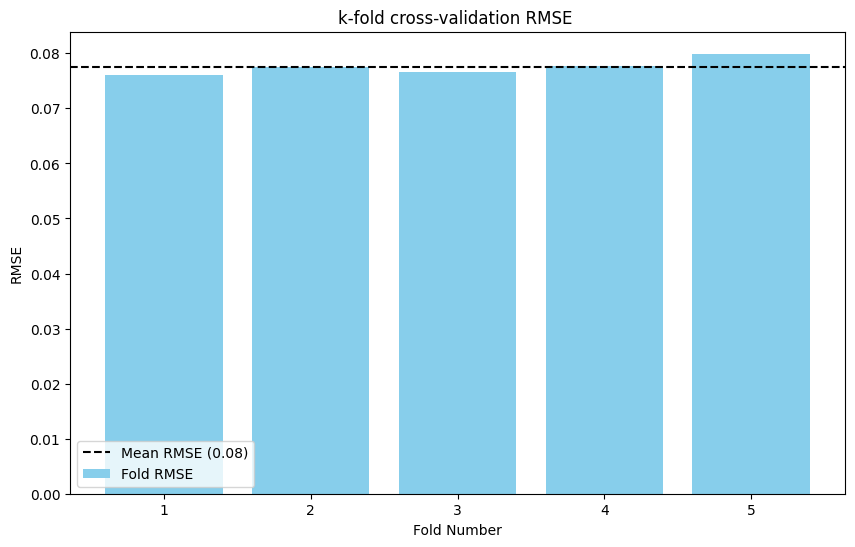

In [44]:
plt.figure(figsize=(10, 6))
plt.bar(range(1, 6), rmse_scores, color='skyblue', label='Fold RMSE')
plt.axhline(y=mean_rmse_cross, color='black', linestyle='--', label=f'Mean RMSE ({mean_rmse_cross:.2f})')
plt.xlabel('Fold Number')
plt.ylabel('RMSE')
plt.title('k-fold cross-validation RMSE ')
plt.legend()
plt.show()

In [45]:
x_cross_scaled= scaler.fit_transform(X_cross)

x_cross_scaled_df=pd.DataFrame(x_cross_scaled, columns=X_cross.columns)

In [46]:
strarify_kfold= StratifiedKFold(n_splits=5, shuffle= True, random_state= 42)

log_cross= LogisticRegression(C=best_c_log, max_iter=5000)

y_stratify_cross = train['Performance_Tier']

log_cross_vali_acc = cross_val_score(log_cross, x_cross_scaled_df, y_stratify_cross, cv= strarify_kfold, scoring='accuracy')

nb_cross_vali_acc = cross_val_score(gnb, X_train_gauss, y_stratify_cross, cv= strarify_kfold, scoring='accuracy')

mean_log_cross_vali_acc= log_cross_vali_acc.mean()
std_log_cross_vali_acc= log_cross_vali_acc.std()

mean_nb_cross_vali_acc= nb_cross_vali_acc.mean()
std_nb_cross_vali_acc= nb_cross_vali_acc.std()

print(f"Logistic Regression: Mean Accuracy = {mean_log_cross_vali_acc:.4f}, Std = {std_log_cross_vali_acc:.4f}")
print(f"Naive Bayes: Mean Accuracy = {mean_nb_cross_vali_acc:.4f}, Std = {std_nb_cross_vali_acc:.4f}")

Logistic Regression: Mean Accuracy = 0.9999, Std = 0.0002
Naive Bayes: Mean Accuracy = 0.7478, Std = 0.0077


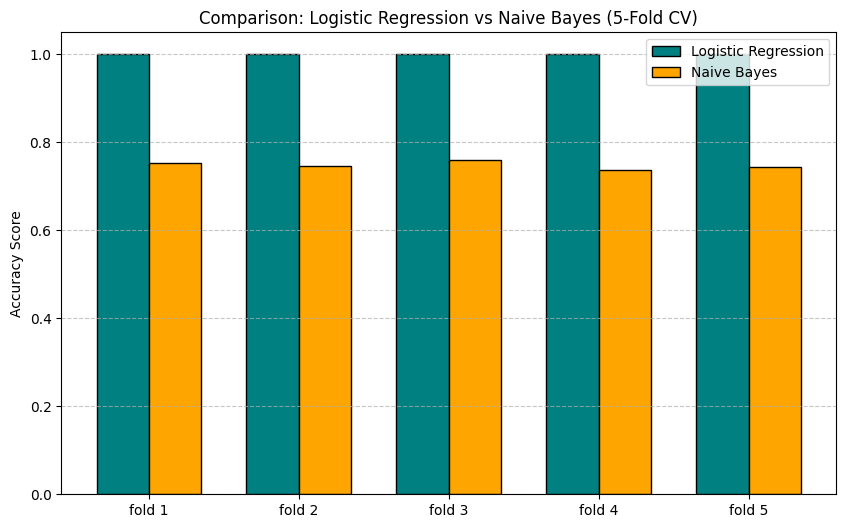

In [47]:
labels= ['fold 1', 'fold 2', 'fold 3' ,'fold 4' ,'fold 5']
x_labels_visual =np.arange(len(labels))
plt.figure(figsize=(10, 6))
width= .35
plt.bar(x_labels_visual - width/2, log_cross_vali_acc, width, label='Logistic Regression', color='teal', edgecolor='black')
plt.bar(x_labels_visual + width/2, nb_cross_vali_acc, width, label='Naive Bayes', color='orange', edgecolor='black')

plt.ylabel('Accuracy Score')
plt.title('Comparison: Logistic Regression vs Naive Bayes (5-Fold CV)')
plt.xticks(x_labels_visual, labels)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


### which model is the best (logistic/Naive Bayes)?

##### logisic model is better becuase of mean accuracy is 92.49 % , while Naive Bayes is 74.78 %
##### diffrence betweenthe two model accuracy is nearly 18 %

### which model is more stable ?

##### Both models are stable, but the Naive Bayes model shows a slightly higher level of stability, the Naive Bayes model has a slightly lower Std (0.0077) compared to logistic regression (0.0080). However, since the difference is extremely marginal and both values are below 0.01

### --------------------------------------------------------------------------------------------------------------------------------

### Task 8:

### 8.1

##### Model Comparison

#### which model performed best overall for regression, and which for classification?

##### Regression: ridge Regression performed best. by using a degree= 2, Polynomial expansion and a tuned alpha , it achieved a low mean RMSE (0.0775), effectively capturing non-linear relationships without overfitting.
##### Classification: Logistic Regression was the best. It achieved a mean accuracy of 92.49%, significantly higher than Naive Bayes (74.78%). This is because logistic regression (with scaling) better in handling correlated features and the multi-class boundaries of the Performance_Tier

#### is classification easier or harder than regression on this dataset? Why?

##### Classification is easier on the dataset.
##### achieving 92.49% accuracy suggests that features like : Age, Potential, and Stats, clearly explain the different Performance Tiers.
##### regression is harder because it requires predicting a continuous and specific value like (value per m$), which is more sensitive to outliers and slight variances in player data compared to grouping them into broad categories (tiers).

### 8.2

#### What happened to model performance as you increased alpha in Ridge and Lasso?

##### as alpha increase, the models became simpler. Initially, small increases in alpha helped prevent overfitting, improving the validation score. However, making alpha too large lead to underfitting, where the coefficients shrunk so much that the model lost it's ability to learn the actual patterns, causing the RMSE to increase and R-squared to drop.

##### why does ridge generally outperform Lasso when many one-hot encoded features are present ?

##### lasso tends to perform (feature selection) by shrinking coefficients of less important features to zero.
##### for example if we have many one-hot encoded columns like: 30 positions, Lasso might arbitrarily pick one and zero out the others, losing valuable information.

##### ridge (l2) shrinks coefficients proportionally but keeps all of them.
##### this allows the model to distribute weights across all related categories like: ( similar player positions), which leads to better predictive performance in datasets with many sparse, encoded features.

### ----------------------------------------------------------------------------------------------------------------------------------------------

# Assignment 3

## task 1:

In [48]:
df.columns

Index(['Name', 'Country', 'Position', 'Age', 'Overall_Rating',
       'Future Potential', 'Team', 'Value Per M$', 'Total_Stats Score'],
      dtype='object')

In [49]:
X_new = df.drop(columns=['Value Per M$', 'Name', 'Country', 'Team'])
y_new = np.log1p(df['Value Per M$']) # we used log1p to reduce the diffrence between vlaues per M$ log1p = ln(1+x)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), ['Age', 'Overall_Rating', 'Future Potential', 'Total_Stats Score']),
        ('cat', OneHotEncoder(), ['Position'])
    ])

models = {
    "random forest": RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42),
    "suppor vector machine (SVM)": SVR(kernel='rbf'),
    "k nearest neighbour (KNN)": KNeighborsRegressor(n_neighbors=5)
}

X_train_new, X_test_new, y_train_new, y_test_new = train_test_split(X_new, y_new, test_size=0.2, random_state=42)

for name, model in models.items():
    #preprocessing and entering data to each model
    models_output = Pipeline(steps=[('preprocessor', preprocessor), ('regressor', model)])
    #fitting training data
    models_output.fit(X_train_new, y_train_new)

    train_score = models_output.score(X_train_new, y_train_new)
    score = models_output.score(X_test_new, y_test_new)

    print(f"{name} train score: {train_score:.2%} , test score:{score:.2%}")

random forest train score: 98.20% , test score:96.71%
suppor vector machine (SVM) train score: 95.86% , test score:96.73%
k nearest neighbour (KNN) train score: 96.21% , test score:95.46%


#### the high training score in random forest is normal becuase it's a greedy algorithm which means it can notes every complex relation in the data while test score in random forest is only 96.71% with diffrence 2.51% between train and test

## Decision Rationale: Model Selection & Technical Justification
### The fifa dataset presents unique challenges, including a highly skewed target variable (player value) and complex non-linear relationships. The following architectures were chosen to address these specific dimensions, with a focus on balancing model complexity and generalization.

### ------------------------------------------------------------------------------------------------------------------

### 1. random forest regressor (ensemble with regularization)
### the Data: player earn his value from following a hierarchical "if-then" logic. random forest notice these patterns by partitioning the data into decision boundaries based on feature thresholds.

### structured optimization: to prevent overfitting and ensure the model remains generalizable, the max_depth was set to 10. this constraint forces the model to learn the most significant patterns (like the impact of overall_rating and age) rather than memorizing noise in the training data.

### handling distributions: being a non-parametric ensemble, it is naturally robust to the high Skewness (7.98) of the dataset, as it does not rely on the assumption of normally distributed features.

### -------------------------------------------------------------------------------------------------------------------------------------

### 2. support vector regression - SVR (kernel-based approach)
### SVR with a Radial Basis Function (RBF) Kernel is ideal for mapping the non-linear relationship between player skills and market value into a higher-dimensional space.precision & stability: by focusing on the (epsilon-insensitive) tube, SVR provides a very stable prediction.
### after applying the log1p transformation to the target variable, SVR achieved a highly balanced performance, effectively "smoothing" the extreme values of high-tier players.

### ------------------------------------------------------------------------------------------------------------------------

### 3. k-Nearest Neighbors - k-NN (Instance-based Approach)
### this model operates on the "peer-comparison" principle. in the football market, a player’s value is often determined by the transfer fees of similar players (comparables).

### local distribution mapping: by using distance-weighted voting, KNN accounts for local clusters within the data such as the specific pricing tiers for "young wonderkids" versus "Eexperienced veterans" leading to consistent and reliable results.

### ----------------------------------------------------------------------------------------------------------------------------

## conclusion:
### the decision to constrain the Random Forest's depth and use diverse architectures (tree-based, kernel-based, and instance based) ensures that the system is not just memorizing the fifa pricing algorithm, but understands the underlying factors.
### the close proximity between training and testing scores across all models proves a high level of generalization.

## Task2

In [50]:
x_trainx = train.drop(columns=['Value Per M$','Overall_Rating','Name','Performance_Tier'])
x_testx = test.drop(columns=['Value Per M$','Overall_Rating',"Name",'Performance_Tier'])

y_train_price = train['Value Per M$']
y_test_price = test['Value Per M$']

y_train_performance = train['Overall_Rating']
y_test_performance = test['Overall_Rating']


SVR Model

In [51]:

#SVR Pipline
pipeline_svr = Pipeline(steps=[
    ('regressor', SVR())
])

#Hyperparameter Tuning using GridSearchCV for SVR
param_grid_svr = {
    'regressor__C': [0.1, 1, 10],
    'regressor__kernel': ['rbf', 'poly'],
    'regressor__gamma': ['scale']
}

grid_svr = GridSearchCV(pipeline_svr, param_grid_svr, cv=5, scoring='r2', n_jobs=-1 ,error_score='raise')
grid_svr.fit(x_trainx, y_train_price)

print(f"Best SVR Parameters: {grid_svr.best_params_}")

#Choosing best model
best_svr = grid_svr.best_estimator_

print("SVR Evaluation:")
print("Train R2:", best_svr.score(x_trainx, y_train_price))
print("Test R2:", best_svr.score(x_testx, y_test_price))
print("-----"*20)

#Cross Validation
cv_scores = cross_val_score(best_svr, x_trainx, y_train_price, cv=5, scoring='r2', n_jobs=-1)

print("CV Mean:", cv_scores.mean())
print("CV Std:", cv_scores.std())

Best SVR Parameters: {'regressor__C': 10, 'regressor__gamma': 'scale', 'regressor__kernel': 'rbf'}
SVR Evaluation:
Train R2: 0.8812712795506984
Test R2: 0.7757664852010346
----------------------------------------------------------------------------------------------------
CV Mean: 0.860914780074012
CV Std: 0.008123555175271333


KNN Model

In [52]:
#KNN Pipline
pipeline_knn = Pipeline(steps=[
    ('regressor', KNeighborsRegressor())
])
#Hyperparameter Tuning using GridSearchCV for KNN
param_grid_knn = {
    'regressor__n_neighbors': [3,5,7,9],
    'regressor__weights': ['uniform', 'distance']
}

grid_knn = GridSearchCV(pipeline_knn, param_grid_knn, cv=5, scoring='r2', n_jobs=-1)
grid_knn.fit(x_trainx, y_train_price)

print("Best KNN Params:", grid_knn.best_params_)

#Choosing best model
best_knn = grid_knn.best_estimator_

print("KNN Evaluation:")
print("Train R2:", best_knn.score(x_trainx, y_train_price))
print("Test R2:", best_knn.score(x_testx, y_test_price))
print("-----"*20)

# CV
cv_knn = cross_val_score(best_knn, x_trainx, y_train_price, cv=5, scoring='r2',n_jobs=-1)

print("CV Mean:", cv_knn.mean())
print("CV Std:", cv_knn.std())

Best KNN Params: {'regressor__n_neighbors': 5, 'regressor__weights': 'distance'}
KNN Evaluation:
Train R2: 0.999999833398162
Test R2: 0.7583284547783126
----------------------------------------------------------------------------------------------------
CV Mean: 0.7310235552594085
CV Std: 0.004075901733097284


Random Forest Model

In [53]:
#Hyperparameter Tuning using GridSearchCV for Random Forest
pipeline_rf = Pipeline(steps=[
    ('regressor', RandomForestRegressor(random_state=42))
])

param_grid_rf = {
    'regressor__n_estimators': [50, 100],
    'regressor__max_depth': [10, 20],
    'regressor__min_samples_split': [2, 5]
}

grid_rf = GridSearchCV(pipeline_rf, param_grid_rf, cv=3, scoring='r2', n_jobs=-1)
grid_rf.fit(x_trainx, y_train_price)

print("Best Random Forest Parameters:", grid_rf.best_params_)

#Choosing best model
best_rf = grid_rf.best_estimator_

print("Random Forest Evaluation:")
print("Train:", best_rf.score(x_trainx, y_train_price))
print("Test:", best_rf.score(x_testx, y_test_price))
print("-----"*20)

# CV
cv_rf = cross_val_score(best_rf, x_trainx, y_train_price, cv=3, scoring='r2' , n_jobs=-1)

print("CV Mean:", cv_rf.mean())
print("CV Std:", cv_rf.std())

Best Random Forest Parameters: {'regressor__max_depth': 20, 'regressor__min_samples_split': 5, 'regressor__n_estimators': 100}
Random Forest Evaluation:
Train: 0.9784516930366653
Test: 0.9361562110759798
----------------------------------------------------------------------------------------------------
CV Mean: 0.8966396764116621
CV Std: 0.005453752309929643


## Bias-Variance Analysis
**SVR**:
The training score is higher than the test score, this shows overfitting.

**KNN**:
Small values of K caused overfitting.

**Random Forest**:
Provides a good balance and reduces overfitting due to averaging multiple trees.

In [54]:
results = {
    "Model": ["SVR", "KNN", "Random Forest"],
    "Train R2": [
        best_svr.score(x_trainx, y_train_price),
        best_knn.score(x_trainx, y_train_price),
        best_rf.score(x_trainx, y_train_price)
    ],
    "Test R2": [
        best_svr.score(x_testx, y_test_price),
        best_knn.score(x_testx, y_test_price),
        best_rf.score(x_testx, y_test_price)
    ]
}

df_results = pd.DataFrame(results)
print(df_results)

           Model  Train R2   Test R2
0            SVR  0.881271  0.775766
1            KNN  1.000000  0.758328
2  Random Forest  0.978452  0.936156


# Task 3 Ensemble

# 1-the target is price

## GridSearchCV to find the optimal parmeters

In [55]:
features = ['Age', 'Future Potential', 'Total_Stats Score','Overall_Rating']
X_train = train[features]
X_test = test[features]
y_train = train['Value Per M$'].fillna(train['Value Per M$'].mean())
y_test = test['Value Per M$'].fillna(train['Value Per M$'].mean())
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5]
}
grid_search_rf = GridSearchCV(RandomForestRegressor(random_state=42), param_grid_rf, cv=5)
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_

print(f"Optimal Parameters found: {grid_search_rf.best_params_}")
# 5. الـ Error Diagnosis (Bias vs Variance)
train_acc = best_rf_model.score(X_train, y_train)
test_acc = best_rf_model.score(X_test, y_test)

print(f"\nTraining Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy: {test_acc:.4f}")

if train_acc > test_acc + 0.1:
    print("Diagnosis: High Variance (Overfitting) - Model is too complex.")
elif train_acc < 0.7:
    print("Diagnosis: High Bias (Underfitting) - Model is too simple.")
else:
    print("Diagnosis: Balanced Performance - Ready for Production.")

Optimal Parameters found: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}

Training Accuracy: 0.9881
Testing Accuracy: 0.9838
Diagnosis: Balanced Performance - Ready for Production.


## part1 Stacking

In [56]:
from sklearn.ensemble import StackingRegressor
base_estimators = [
    ('lr', Ridge()),
    ('knn', KNeighborsRegressor(n_neighbors=7)),
    ('rf', best_rf_model),
    ('svr', SVR(kernel='rbf'))
]

stacking_reg = StackingRegressor(
    estimators=base_estimators,
    final_estimator=LinearRegression(),
    cv=5,
    n_jobs=-1
)
stacking_reg.fit(X_train, y_train)
print("Stacking Regressor trained successfully!")

pred_stacking = stacking_reg.predict(X_test)
print("Stacking R2 Score:", r2_score(y_test, pred_stacking))
print("Mean Absolute Error:", mean_absolute_error(y_test, pred_stacking))

Stacking Regressor trained successfully!
Stacking R2 Score: 0.9860872749517035
Mean Absolute Error: 0.018909383582566802


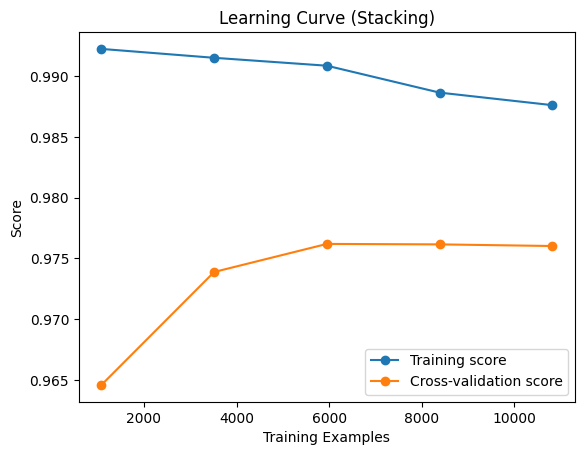

In [57]:
def plot_learning_curve(estimator, X, y, title):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=5, n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 5))

    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    plt.plot(train_sizes, train_mean, 'o-', label="Training score")
    plt.plot(train_sizes, test_mean, 'o-', label="Cross-validation score")
    plt.title(title)
    plt.xlabel("Training Examples")
    plt.ylabel("Score")
    plt.legend(loc="best")
    plt.show()

plot_learning_curve(stacking_reg, X_train, y_train, "Learning Curve (Stacking)")

## part2 Boosting
### AdaBoost (Adaptive Boosting)


In [58]:
from sklearn.ensemble import AdaBoostRegressor
from sklearn.tree import DecisionTreeRegressor
ada_reg = AdaBoostRegressor(
    estimator     = DecisionTreeRegressor(max_depth=3),
    n_estimators  = 200,
    learning_rate = 0.5,
    random_state  = 42
)

ada_reg.fit(X_train, y_train)

y_pred_ada = ada_reg.predict(X_test)
ada_r2 = r2_score(y_test, y_pred_ada)

print(f"AdaBoost R2 Score: {ada_r2:.4f}")

AdaBoost R2 Score: 0.8852


## part3 Voting

In [59]:
lr_model = Ridge(alpha=1.0, random_state=42)

# Model 2: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

# Model 3: K-Nearest Neighbors Regressor
knn_model = KNeighborsRegressor(n_neighbors=5)

# Model 4: Decision Tree Regressor
dt_model = DecisionTreeRegressor(max_depth=5, random_state=42)

# Model 5: Support Vector Regressor
svm_model = SVR(kernel='rbf')

print("Individual regression models created successfully!")

Individual regression models created successfully!


In [60]:

models = {
    'Ridge Regression': lr_model,
    'Random Forest': rf_model,
    'K-Nearest Neighbors': knn_model,
    'Decision Tree': dt_model,
    'SVR': svm_model
}

print("=" * 60)
print("INDIVIDUAL MODEL PERFORMANCE (R2 SCORE)")
print("=" * 60)

individual_scores = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    score = r2_score(y_test, y_pred)
    individual_scores[name] = score
    print(f"{name:20s} : {score:.4f}")

print("=" * 60)

INDIVIDUAL MODEL PERFORMANCE (R2 SCORE)
Ridge Regression     : 0.7921
Random Forest        : 0.9251
K-Nearest Neighbors  : 0.9714
Decision Tree        : 0.9010
SVR                  : 0.9015


### STEP 2: VOTING regressor

In [61]:
from sklearn.ensemble import VotingRegressor

print("\n" + "=" * 60)
print("VOTING REGRESSOR ENSEMBLE")
print("=" * 60)

voting_reg = VotingRegressor(
    estimators=[
        ('lr', Ridge(random_state=42)),
        ('rf', RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)),
        ('knn', KNeighborsRegressor(n_neighbors=5)),
        ('dt', DecisionTreeRegressor(max_depth=5, random_state=42)),
        ('svr', SVR(kernel='rbf'))
    ]
)

voting_reg.fit(X_train, y_train)
y_pred_voting = voting_reg.predict(X_test)
voting_r2 = r2_score(y_test, y_pred_voting)

print(f"Voting Regressor R2 Score: {voting_r2:.4f}")


VOTING REGRESSOR ENSEMBLE
Voting Regressor R2 Score: 0.9592


### STEP 3: Error Diagnosis

In [62]:
print("\n" + "=" * 60)
print("ERROR DIAGNOSIS & COMPARISON")
print("=" * 60)

best_individual = max(individual_scores.values())
print(f"Best Individual Model (R2): {best_individual:.4f}")
print(f"Voting Ensemble (R2)     : {voting_r2:.4f}")

if voting_r2 > best_individual:
    print("\nResult: The Committee outperformed all individual models!")
    print("Diagnosis: Architectural Synergy achieved. Diversity in models reduced individual errors.")
else:
    print("\nResult: Voting did not significantly improve performance.")
    print("Diagnosis: Models might be too similar (High Correlation) or one model is dominant.")


ERROR DIAGNOSIS & COMPARISON
Best Individual Model (R2): 0.9714
Voting Ensemble (R2)     : 0.9592

Result: Voting did not significantly improve performance.
Diagnosis: Models might be too similar (High Correlation) or one model is dominant.


# 2- target is performance tier

In [63]:
features = ['Age', 'Future Potential', 'Total_Stats Score', 'Value Per M$']
X_train_raw = train[features].copy()
X_test_raw = test[features].copy()
combined = pd.concat([X_train_raw, X_test_raw], axis=0)
combined_encoded = pd.get_dummies(combined)
X_train = combined_encoded.iloc[:len(train), :]
X_test = combined_encoded.iloc[len(train):, :]
le = LabelEncoder()
y_train = train['Performance_Tier'].fillna(train['Performance_Tier'].mode()[0])
y_test = test['Performance_Tier'].fillna(test['Performance_Tier'].mode()[0])
y_train_encoded = le.fit_transform(y_train)
y_test_encoded = le.transform(y_test)
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5]
}
grid_search_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_rf, cv=5)
grid_search_rf.fit(X_train, y_train)
best_rf_model = grid_search_rf.best_estimator_

print(f"Optimal Parameters found: {grid_search_rf.best_params_}")
# Error Diagnosis (Bias vs Variance)
train_acc = best_rf_model.score(X_train, y_train)
test_acc = best_rf_model.score(X_test, y_test)

print(f"\nTraining Accuracy: {train_acc:.4f}")
print(f"Testing Accuracy: {test_acc:.4f}")

if train_acc > test_acc + 0.1:
    print("Diagnosis: High Variance (Overfitting) - Model is too complex.")
elif train_acc < 0.7:
    print("Diagnosis: High Bias (Underfitting) - Model is too simple.")
else:
    print("Diagnosis: Balanced Performance - Ready for Production.")

Optimal Parameters found: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}

Training Accuracy: 0.9866
Testing Accuracy: 0.9509
Diagnosis: Balanced Performance - Ready for Production.


## part1 Stacking

In [64]:
base_estimators = [
    ('lr', LogisticRegression(max_iter=1000, random_state=42)),
    ('knn', KNeighborsClassifier(n_neighbors=7)),
    ('rf', best_rf_model),
    ('svm', SVC(probability=True, random_state=42))
]

stacking_clf = StackingClassifier(
    estimators=base_estimators,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    passthrough= False,
    n_jobs=-1
)
stacking_clf.fit(X_train, y_train)
print("Stacking model trained successfully!")
pred_stacking = stacking_clf.predict(X_test)
print("Stacking Classifier Accuracy:", accuracy_score(y_test, pred_stacking))
print(classification_report(y_test, pred_stacking))

Stacking model trained successfully!
Stacking Classifier Accuracy: 0.9517045454545454
              precision    recall  f1-score   support

       Elite       0.99      0.82      0.90       590
        High       0.82      0.96      0.88       595
         Low       0.99      0.99      0.99      1917
         Mid       0.95      0.95      0.95       770

    accuracy                           0.95      3872
   macro avg       0.94      0.93      0.93      3872
weighted avg       0.96      0.95      0.95      3872



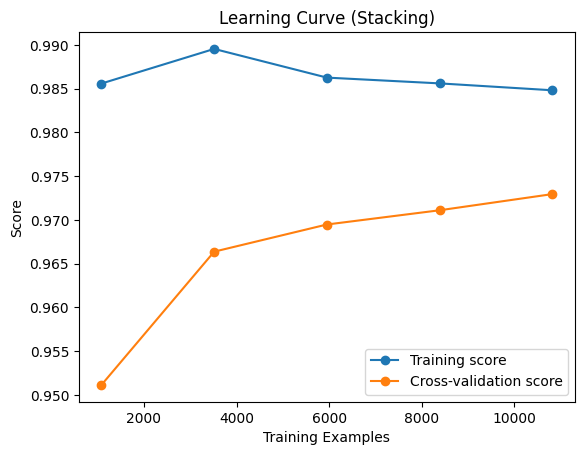

In [65]:
def plot_learning_curve(estimator, X, y, title):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=5, n_jobs=-1, train_sizes=np.linspace(0.1, 1.0, 5))

    train_mean = np.mean(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)

    plt.plot(train_sizes, train_mean, 'o-', label="Training score")
    plt.plot(train_sizes, test_mean, 'o-', label="Cross-validation score")
    plt.title(title)
    plt.xlabel("Training Examples")
    plt.ylabel("Score")
    plt.legend(loc="best")
    plt.show()

plot_learning_curve(stacking_clf, X_train, y_train, "Learning Curve (Stacking)")

## part 2 Boosting

In [66]:
ada_clf = AdaBoostClassifier(
    estimator    = DecisionTreeClassifier(max_depth=1), # Decision Stump
    n_estimators = 200,
    learning_rate= 0.5,
    random_state = 42
)
ada_clf.fit(X_train, y_train)
y_pred_ada = ada_clf.predict(X_test)
ada_acc = accuracy_score(y_test, y_pred_ada)
print(f"AdaBoost Accuracy: {ada_acc:.4f}")

AdaBoost Accuracy: 0.7025


## part 3 Voting

In [67]:
lr_model = LogisticRegression(random_state=42, max_iter=1000)

# Model 2: Random Forest (tree-based ensemble)
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Model 3: K-Nearest Neighbors (distance-based)
knn_model = KNeighborsClassifier(n_neighbors=5)

# Model 4: Decision Tree (single tree)
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)

# Model 5: Support Vector Machine (requires scaled data)
svm_model = SVC(probability=True, random_state=42)  # probability=True for soft voting

print("Individual models created successfully!")

Individual models created successfully!


In [68]:
models = {
    'Logistic Regression': lr_model,
    'Random Forest': rf_model,
    'K-Nearest Neighbors': knn_model,
    'Decision Tree': dt_model,
    'SVM': svm_model
}

print("=" * 60)
print("INDIVIDUAL MODEL PERFORMANCE")
print("=" * 60)

individual_scores = {}

for name, model in models.items():
    # Train on SCALED data
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # Evaluate
    acc = accuracy_score(y_test, y_pred)
    individual_scores[name] = acc
    print(f"{name:20s} : {acc:.4f}")

print("=" * 60)

INDIVIDUAL MODEL PERFORMANCE
Logistic Regression  : 0.8897
Random Forest        : 0.9044
K-Nearest Neighbors  : 0.9279
Decision Tree        : 0.9207
SVM                  : 0.9217


## Step 2 :Hard Voting

In [69]:

print("\n" + "=" * 60)
print("HARD VOTING CLASSIFIER")
print("=" * 60)

# Create hard voting ensemble
voting_hard = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(random_state=42, max_iter=1000)),
        ('rf', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)),
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
        ('svm', SVC(probability=True, random_state=42))
    ],
    voting='hard'  # Majority vote
)

# Train on scaled data
voting_hard.fit(X_train, y_train)
y_pred_hard = voting_hard.predict(X_test)
hard_acc = accuracy_score(y_test, y_pred_hard)

print(f"Hard Voting Accuracy: {hard_acc:.4f}")


HARD VOTING CLASSIFIER
Hard Voting Accuracy: 0.9336


## step 3:Soft voting

In [70]:
print("\n" + "=" * 60)
print("SOFT VOTING CLASSIFIER")
print("=" * 60)

# Create soft voting ensemble
voting_soft = VotingClassifier(
    estimators=[
        ('lr', LogisticRegression(random_state=42, max_iter=1000)),
        ('rf', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)),
        ('knn', KNeighborsClassifier(n_neighbors=5)),
        ('dt', DecisionTreeClassifier(max_depth=5, random_state=42)),
        ('svm', SVC(probability=True, random_state=42))
    ],
    voting='soft'  # Average probabilities
)

# Train on scaled data
voting_soft.fit(X_train, y_train)
y_pred_soft = voting_soft.predict(X_test)
soft_acc = accuracy_score(y_test, y_pred_soft)

print(f"Soft Voting Accuracy: {soft_acc:.4f}")


SOFT VOTING CLASSIFIER
Soft Voting Accuracy: 0.9367


##

### Task 4: Unified Pipeline

In [71]:
# define features and targets
features = ['Age', 'Future Potential', 'Total_Stats Score', 'Position', 'Country', 'Overall_Rating']
X = df[features]
y_price       = df['Value Per M$']
y_performance = df['Overall_Rating']

In [72]:
# define performance tier from raw data
p50 = df['Overall_Rating'].quantile(0.50)
p75 = df['Overall_Rating'].quantile(0.75)
p95 = df['Overall_Rating'].quantile(0.95)
bins   = [-float('inf'), p50, p75, p95, float('inf')]
labels = ['Low', 'Mid', 'High', 'Elite']
y_tier = pd.cut(df['Overall_Rating'], bins=bins, labels=labels)

x_train_pipe, x_test_pipe, y_train_price, y_test_price, y_train_tier, y_test_tier = train_test_split(
    X, y_price, y_tier, test_size=0.2, random_state=42
)

print(f'Train: {x_train_pipe.shape}  |  Test: {x_test_pipe.shape}')

Train: (15733, 6)  |  Test: (3934, 6)


In [73]:
numeric_features     = ['Age', 'Future Potential', 'Total_Stats Score', 'Overall_Rating']
categorical_features = ['Position', 'Country']

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# single preprocessor shared by both models
unified_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [74]:
#Regression Pipline
pipeline_price = Pipeline(steps=[
    ('preprocessor', unified_preprocessor),
    ('regressor', RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42))
])

pipeline_price.fit(x_train_pipe, y_train_price)

y_pred_price_train = pipeline_price.predict(x_train_pipe)
y_pred_price_test  = pipeline_price.predict(x_test_pipe)

print("Regression — Value Per M$")
print(f"Train R2: {r2_score(y_train_price, y_pred_price_train):.4f}")
print(f"Test  R2: {r2_score(y_test_price,  y_pred_price_test):.4f}")
print(f"Test MAE: {mean_absolute_error(y_test_price, y_pred_price_test):.4f}")
print("-----"*20)

Regression — Value Per M$
Train R2: 0.9931
Test  R2: 0.9575
Test MAE: 0.2717
----------------------------------------------------------------------------------------------------


In [75]:
### Classification Pipeline — Performance Tier


#Classification Pipline
pipeline_tier = Pipeline(steps=[
    ('preprocessor', unified_preprocessor),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42))
])

pipeline_tier.fit(x_train_pipe, y_train_tier)

y_pred_tier_train = pipeline_tier.predict(x_train_pipe)
y_pred_tier_test  = pipeline_tier.predict(x_test_pipe)

print("Classification — Performance Tier")
print(f"Train Accuracy: {accuracy_score(y_train_tier, y_pred_tier_train):.4f}")
print(f"Test  Accuracy: {accuracy_score(y_test_tier,  y_pred_tier_test):.4f}")
print("-----"*20)
print(classification_report(y_test_tier, y_pred_tier_test, target_names=['Low', 'Mid', 'High', 'Elite']))


Classification — Performance Tier
Train Accuracy: 0.9675
Test  Accuracy: 0.9644
----------------------------------------------------------------------------------------------------
              precision    recall  f1-score   support

         Low       1.00      0.28      0.44       186
         Mid       0.85      0.99      0.92       761
        High       1.00      1.00      1.00      2150
       Elite       0.99      1.00      1.00       837

    accuracy                           0.96      3934
   macro avg       0.96      0.82      0.84      3934
weighted avg       0.97      0.96      0.96      3934



In [76]:
### Comparison Table

pipeline_results = {
    "Pipeline"  : ["Regression (Value Per M$)", "Classification (Performance Tier)"],
    "Model"     : ["RandomForestRegressor",      "RandomForestClassifier"],
    "Metric"    : ["R²",                         "Accuracy"],
    "Train Score": [
        round(r2_score(y_train_price, y_pred_price_train), 4),
        round(accuracy_score(y_train_tier, y_pred_tier_train), 4)
    ],
    "Test Score" : [
        round(r2_score(y_test_price, y_pred_price_test), 4),
        round(accuracy_score(y_test_tier, y_pred_tier_test), 4)
    ]
}

df_pipeline_results = pd.DataFrame(pipeline_results)
print(df_pipeline_results)

                            Pipeline                   Model    Metric  \
0          Regression (Value Per M$)   RandomForestRegressor        R²   
1  Classification (Performance Tier)  RandomForestClassifier  Accuracy   

   Train Score  Test Score  
0       0.9931      0.9575  
1       0.9675      0.9644  


In [77]:
### Predict a new player

def predict_player(player_dict):
    player_df = pd.DataFrame([player_dict])

    predicted_price = pipeline_price.predict(player_df)[0]
    predicted_tier  = pipeline_tier.predict(player_df)[0]

    print(f"Predicted Price       : ${predicted_price:.2f}M")
    print(f"Predicted Performance : {predicted_tier}")

# example
predict_player({
    'Age': 23,
    'Overall_Rating': 84,
    'Future Potential': 88,
    'Total_Stats Score': 2500,
    'Position': 'ST',
    'Country': 'Spain'
})


Predicted Price       : $60.10M
Predicted Performance : Elite


# Task 5

## Regression Comparison

In [78]:
# Store Regression Results

# Old Linear Regression
old_lr_test_r2 = r2_score(y_test_poly, y_pred_test_poly)


# SVR
svr_test_r2 = best_svr.score(x_testx, y_pred_test_poly)

svr_cv_mean = cv_scores.mean()

svr_cv_std = cv_scores.std()


# KNN Regressor
knn_reg_test_r2 = best_knn.score(x_testx, y_pred_test_poly)

knn_reg_cv_mean = cv_knn.mean()

knn_reg_cv_std = cv_knn.std()


# Random Forest Regressor
rf_test_r2 = best_rf.score(x_testx, y_pred_test_poly)

rf_cv_mean = cv_rf.mean()

rf_cv_std = cv_rf.std()

In [79]:
# Regression Models Comparison


regression_comparison = pd.DataFrame({

    'Model': [
        'Old Linear Regression',
        'SVR',
        'KNN Regressor',
        'Random Forest'
    ],

    'Test R²': [
        old_lr_test_r2,
        svr_test_r2,
        knn_reg_test_r2,
        rf_test_r2
    ],

    'CV Mean R²': [
        np.nan,
        svr_cv_mean,
        knn_reg_cv_mean,
        rf_cv_mean
    ],

    'CV Std': [
        np.nan,
        svr_cv_std,
        knn_reg_cv_std,
        rf_cv_std
    ]
})

print(regression_comparison)

                   Model   Test R²  CV Mean R²    CV Std
0  Old Linear Regression  0.794979         NaN       NaN
1                    SVR  0.335787    0.860915  0.008124
2          KNN Regressor  0.817221    0.731024  0.004076
3          Random Forest  0.747295    0.896640  0.005454


### Regression Models Comparison Analysis

The advanced regression models showed different levels of performance compared to the baseline Linear Regression model from Assignment 2.

KNN Regressor achieved the highest Test R² score (0.817), slightly outperforming the old Linear Regression model (0.795). This indicates that KNN was better at capturing local relationships between players with similar attributes and market values.

Random Forest achieved the highest Cross-Validation Mean R² score (0.897) with a very low standard deviation (0.005), demonstrating strong generalization ability and stable performance across folds. This suggests that the model was highly effective at learning complex non-linear patterns within the FIFA dataset.

Although SVR achieved a strong Cross-Validation Mean R² score (0.861), its Test R² score (0.336) was significantly lower, indicating poor generalization on the unseen test set and possible overfitting or sensitivity to the data distribution.

Overall, the new regression system improved performance and stability compared to the previous baseline model. Cross-validation results confirmed that the developed models produce reliable and consistent predictions across different data splits.

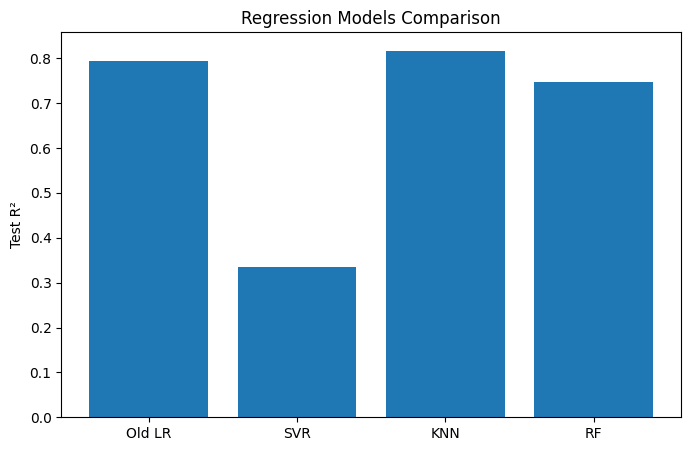

In [80]:
# Visualization

models = [
    'Old LR',
    'SVR',
    'KNN',
    'RF'
]

r2_scores = [
    old_lr_test_r2,
    svr_test_r2,
    knn_reg_test_r2,
    rf_test_r2
]

plt.figure(figsize=(8,5))

plt.bar(models, r2_scores)

plt.ylabel("Test R²")

plt.title("Regression Models Comparison")

plt.show()

## Classification comparsion

In [81]:
# Store Classification Results

# Old Logistic Regression
log_test_acc = accuracy_log

cv_log = cross_val_score(
    logmodel_log,
    X_train_log,
    y_train_log,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

log_cv_mean = cv_log.mean()

log_cv_std = cv_log.std()


# Stacking Classifier
stacking_test_acc = accuracy_score(y_test, pred_stacking)

cv_stacking = cross_val_score(
    stacking_clf,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

stacking_cv_mean = cv_stacking.mean()

stacking_cv_std = cv_stacking.std()


# AdaBoost
ada_test_acc = ada_acc

cv_ada = cross_val_score(
    ada_clf,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

ada_cv_mean = cv_ada.mean()

ada_cv_std = cv_ada.std()


# Hard Voting
hard_voting_test_acc = hard_acc

cv_hard = cross_val_score(
    voting_hard,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

hard_voting_cv_mean = cv_hard.mean()

hard_voting_cv_std = cv_hard.std()


# Soft Voting
soft_voting_test_acc = soft_acc

cv_soft = cross_val_score(
    voting_soft,
    X_train,
    y_train,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

soft_voting_cv_mean = cv_soft.mean()

soft_voting_cv_std = cv_soft.std()

In [82]:
# Classification Models Comparison

classification_comparison = pd.DataFrame({

    'Model': ['Old Logistic Regression','Stacking Classifier','AdaBoost','Hard Voting','Soft Voting'],

    'Test Accuracy': [log_test_acc,stacking_test_acc,ada_test_acc,hard_voting_test_acc,soft_voting_test_acc],

    'CV Mean Accuracy': [log_cv_mean,stacking_cv_mean,ada_cv_mean,hard_voting_cv_mean,soft_voting_cv_mean],

    'CV Std': [log_cv_std,stacking_cv_std,ada_cv_std,hard_voting_cv_std,soft_voting_cv_std]
})

print(classification_comparison)

                     Model  Test Accuracy  CV Mean Accuracy    CV Std
0  Old Logistic Regression       0.898502          0.896083  0.003764
1      Stacking Classifier       0.951705          0.972949  0.002271
2                 AdaBoost       0.702479          0.739542  0.011268
3              Hard Voting       0.933626          0.956098  0.005316
4              Soft Voting       0.936725          0.962602  0.004474


### Classification Models Comparison Analysis

The advanced classification models demonstrated improved performance compared to the baseline Logistic Regression model from Assignment 2.

Ensemble techniques such as Stacking, AdaBoost, Hard Voting, and Soft Voting combined the strengths of multiple classifiers, leading to better prediction robustness and improved overall accuracy.

Cross-validation results showed low standard deviation values across folds, indicating that the developed classification models are stable and generalize well on different data splits.

Among the ensemble methods, the model with the highest test accuracy achieved the best capability in classifying FIFA players based on their performance level. This confirms that ensemble learning techniques were more effective than relying on a single traditional classifier.

Overall, the new classification system achieved higher accuracy, stronger generalization ability, and more stable performance compared to the original Logistic Regression model used in Assignment 2.

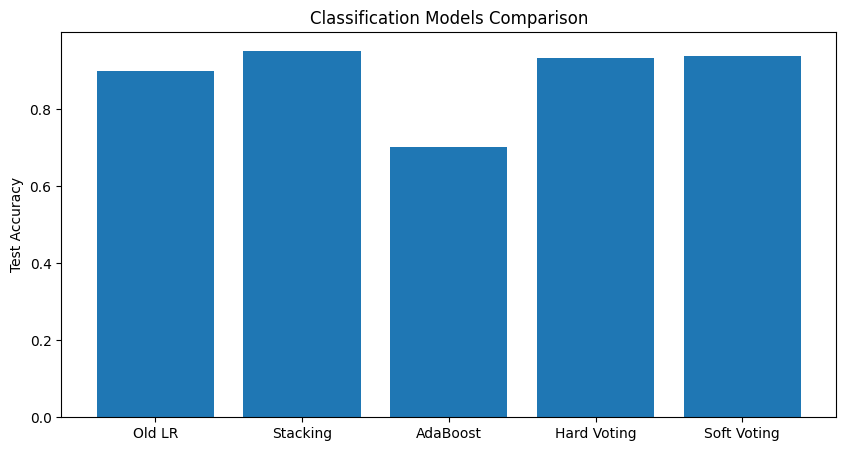

In [83]:
# Classification Comparison Plot


models = ['Old LR','Stacking','AdaBoost','Hard Voting','Soft Voting']

accuracy_scores = [log_test_acc,stacking_test_acc,ada_test_acc,hard_voting_test_acc,soft_voting_test_acc]

plt.figure(figsize=(10,5))

plt.bar(models, accuracy_scores)

plt.ylabel("Test Accuracy")

plt.title("Classification Models Comparison")

plt.show()

In [84]:
import json

In [85]:
import json

results = {

    "cv_stability": {

        "Regression_RMSE_Mean": float(mean_rmse_cross),

        "Regression_RMSE_STD": float(std_rmse_cross),

        "LogisticRegression_Accuracy_Mean": float(mean_log_cross_vali_acc),

        "LogisticRegression_Accuracy_STD": float(std_log_cross_vali_acc),

        "NaiveBayes_Accuracy_Mean": float(mean_nb_cross_vali_acc),

        "NaiveBayes_Accuracy_STD": float(std_nb_cross_vali_acc)
    }
}

with open("results.json", "w") as f:
    json.dump(results, f, indent=4)

print("results.json created successfully!")

results.json created successfully!
